<div align="center" dir="rtl" style="direction:rtl;text-align:center;">

<p><strong>مجموعهٔ آزمون‌های آزمایشی هوش مصنوعی</strong></p>
<p><img src="../src/logo.png" alt="لوگوی آزمون‌های آزمایشی هوش مصنوعی" width="400"></p>
<p>طراح: طاهو</p>
<h1>فرودِ جعبه‌ی سیاه</h1>
<p>سطح ۱ · رگرسیون از صفر و مهندسی ویژگی</p>
<p><strong>در سقوط آزاد، دو برابر شدن زمان سقوط، جابه‌جایی را چهار برابر می‌کند.</strong></p>

</div>


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## مشخصات تسک

### سناریو

یک پهپاد پژوهشی در حال آزمایش سامانهٔ رهاسازی حسگر است. زمان سقوط هر حسگر ثبت شده، اما سنجش موقعیت گاهی از دست می‌رود. مأموریت شما پیش‌بینی **جابه‌جایی عمودی حسگر** با کمک داده‌های رهاسازی‌های پیشین است.

برای حل مسئله، یک تبدیل ویژگی مناسب انتخاب کنید و رگرسیون خطی را خودتان با NumPy پیاده‌سازی کنید. مدل باید از رابطهٔ موجود در داده بیاموزد؛ استفاده از مقدار ثابت فیزیکی برای ساخت مستقیم پاسخ، جایگزین آموزش مدل نیست.

### مدل فیزیکی

در این مسئله سقوط آزاد را در نظر می‌گیریم: سرعت اولیهٔ عمودی صفر، شتاب گرانش ثابت و مقاومت هوا ناچیز است. جابه‌جایی پس از `t` ثانیه از رابطهٔ زیر پیروی می‌کند:

$$d = \frac{1}{2}gt^2$$

`d` بر حسب متر، `t` بر حسب ثانیه و `g = 9.81 m/s²` است. مقدار هدف به‌دلیل نویز سنسور کمی با مقدار نظری تفاوت دارد.

### داده‌ها

| فایل | ستون‌ها | کاربرد |
|---|---|---|
| `data/train/train.csv` | `id`, `time_s`, `displacement_m` | آموزش مدل |
| `data/validation/validation.csv` | `id`, `time_s`, `displacement_m` | ارزیابی محلی و انتخاب ویژگی |
| `data/test/test.csv` | `id`, `time_s` | پیش‌بینی نهایی؛ برچسب در دسترس نیست |

زمان بر حسب ثانیه و جابه‌جایی بر حسب متر است. ستون `id` فقط شناسهٔ ردیف است و نباید به‌عنوان ویژگی مدل استفاده شود.

### کارهایی که باید انجام دهید

1. فایل‌ها را با `pandas` بخوانید و دادهٔ آموزش را بررسی کنید.
2. ویژگی‌های ورودی را با توجه به مدل فیزیکی بسازید.
3. رگرسیون خطی را با عملیات ماتریسی NumPy کامل کنید.
4. عملکرد را با RMSE روی validation بسنجید.
5. روی test پیش‌بینی بگیرید و فایل ارسال را با سلول پایانی بسازید.

### کتابخانه‌ها و محدودیت‌ها

**مجاز:** کتابخانهٔ استاندارد Python، `numpy`, `pandas`, `matplotlib`.

**محدودیت‌ها:** مدل نهایی باید رگرسیون خطی باشد. استفاده از `sklearn`، سرویس‌های اینترنتی، برچسب‌های خصوصی یا ستون `id` به‌عنوان ویژگی مجاز نیست.

### معیار و نمره‌دهی

معیار ارزیابی **RMSE** بر حسب متر است و مقدار کمتر بهتر است. جاج، پیش‌بینی‌ها را با برچسب‌های test محرمانه مقایسه می‌کند. نمرهٔ تسک از ۰ تا ۲۰ محاسبه می‌شود:

- اگر `RMSE > 15` باشد، نمره `0` است.
- اگر `RMSE <= 2` باشد، نمره `20` است.
- در غیر این صورت: `round(20 * (15 - RMSE) / 13)`.

### قالب فایل ارسال

فایل باید `submission.csv` نام داشته باشد و دقیقاً دو ستون `id,prediction` داشته باشد. هر شناسهٔ test باید دقیقاً یک بار درج شود و همهٔ پیش‌بینی‌ها باید عددی و متناهی باشند. سلول پایانی این نوت‌بوک خروجی را می‌سازد و قالبش را بررسی می‌کند.

</div>


train: (1200, 3)
validation: (300, 3)
test: (300, 2)


,id,time_s,displacement_m
0,0,1.48414,10.18043
1,1,4.01952,78.51353
2,2,3.06998,43.98154
3,3,2.53775,31.00607
4,4,2.45205,29.99535


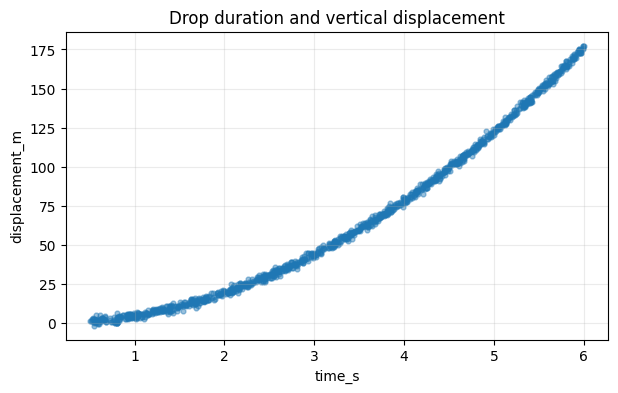

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
train_df = pd.read_csv(DATA_DIR / "train" / "train.csv")
validation_df = pd.read_csv(DATA_DIR / "validation" / "validation.csv")
test_df = pd.read_csv(DATA_DIR / "test" / "test.csv")

print("train:", train_df.shape)
print("validation:", validation_df.shape)
print("test:", test_df.shape)
display(train_df.head())

plt.figure(figsize=(7, 4))
plt.scatter(train_df["time_s"], train_df["displacement_m"], s=12, alpha=0.45)
plt.xlabel("time_s")
plt.ylabel("displacement_m")
plt.title("Drop duration and vertical displacement")
plt.grid(alpha=0.25)
plt.show()


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۲. مهندسی ویژگی

رگرسیون خطی در ویژگی‌هایی که به آن می‌دهیم رابطهٔ خطی می‌آموزد. با توجه به رابطهٔ فیزیکی در مشخصات تسک، تابع `make_features` را کامل کنید. خروجی باید آرایه‌ای دوبعدی با شکل `(تعداد نمونه‌ها، تعداد ویژگی‌ها)` باشد. شناسه را وارد ویژگی‌ها نکنید.

</div>


In [2]:
def make_features(frame: pd.DataFrame) -> np.ndarray:
    """تبدیل ستون‌های ورودی به ماتریس ویژگی دوبعدی NumPy."""
    t = frame["time_s"].to_numpy(dtype=float)
    # TODO: Build suitable feature(s) from t. Return a 2D array with shape (n_samples, n_features).
    raise NotImplementedError


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۳. پیاده‌سازی رگرسیون خطی از صفر

کلاس `ScratchLinearRegression` را فقط با NumPy پیاده‌سازی کنید. در `fit` عرض از مبدأ را اضافه و وزن‌ها را با جبر خطی محاسبه کنید. در `predict` برای هر ردیف یک مقدار پیوسته برگردانید. برای پایداری عددی از `np.linalg.pinv` یا `np.linalg.lstsq` استفاده کنید.

</div>


In [ ]:
class ScratchLinearRegression:
    def __init__(self):
        self.weights = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        # TODO: Add the intercept column and estimate the weights with linear algebra.
        raise NotImplementedError

    def predict(self, X: np.ndarray) -> np.ndarray:
        # TODO: Return continuous predictions.
        raise NotImplementedError


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۴. ارزیابی محلی

مدل را روی train آموزش دهید و RMSE را روی validation محاسبه کنید. از validation برای مقایسهٔ انتخاب‌های ویژگی استفاده کنید؛ برای یادگیری پارامترها یا محاسبهٔ آمار پیش‌پردازش از آن استفاده نکنید.

</div>


In [ ]:
def rmse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

X_train = make_features(train_df)
y_train = train_df["displacement_m"].to_numpy(dtype=float)
X_val = make_features(validation_df)
y_val = validation_df["displacement_m"].to_numpy(dtype=float)

model = ScratchLinearRegression()
model.fit(X_train, y_train)
val_predictions = model.predict(X_val)
print(f"Validation RMSE: {rmse(y_val, val_predictions):.4f} m")


<div dir="rtl" align="right" style="direction:rtl;text-align:right;">

## ۵. پیش‌بینی test و ساخت فایل ارسال

پس از نهایی‌کردن روش، این سلول روی test پیش‌بینی می‌گیرد. متغیر `predictions` باید آرایه‌ای یک‌بعدی با یک مقدار برای هر ردیف test باشد. سپس فایل `submission.csv` با قرارداد مشخص‌شده ساخته می‌شود.

</div>


In [ ]:
# Optionally refit the final model on both train and validation.
# For this simple task, the starter uses the model fitted on train.
X_test = make_features(test_df)
predictions = np.asarray(model.predict(X_test), dtype=float).reshape(-1)

assert len(predictions) == len(test_df), "تعداد پیش‌بینی‌ها با test برابر نیست"
assert np.isfinite(predictions).all(), "predictions دارای NaN یا Inf است"

submission = pd.DataFrame({"id": test_df["id"].to_numpy(), "prediction": predictions})
assert submission.columns.tolist() == ["id", "prediction"]
assert submission["id"].is_unique
submission.to_csv("submission.csv", index=False)
print(f"submission.csv ساخته شد: {len(submission)} پیش‌بینی")
display(submission.head())
